# Ablation Runde 2: Original-Handling, Teacher, Gewichte & Route-Signal

**Ausgangslage (Runde 1):** `v3` (Teacher ja, Original-Zeilen *nicht* im Training) +0.00051 und `v8` (Original mit eigenen Statistiken) +0.00044 waren klar besser als `fs06`; die Route-Features tragen ca. +0.0015.

**Was hier getestet wird**

| Block | Frage |
|---|---|
| Diagnose | Ist der Teacher auf dem Original deutlich "schärfer" als auf Train? (Erklärung für die Redundanz) |
| A | `v3` + `v8` kombiniert |
| B | A ohne `interact_group` und `combos` (schlanker) |
| C | Teacher nur auf **Rohspalten** (ohne gruppenbasierte Features) |
| D | Original-Zeilen **mit kleinem Gewicht** zusätzlich zum Teacher |
| E | Route-Signal vertiefen: welche Route-Teile tragen, zusätzliche Aggregate, Abweichungen zum Route-Mittel, Target-Encoding Route×Class / Route×Reise-Typ |
| Final | Alle Gewinner (≥ Rauschgrenze, in fast allen Folds besser) zusammen testen |

**Projektdateien bleiben unangetastet:** `src/*.py` werden nur importiert, alle Anpassungen passieren im Speicher. Ergebnisse landen in `Results/ablation/round2_results.csv` (Resume möglich).

In [1]:
import os, sys, time, json, warnings, dataclasses
from pathlib import Path
from contextlib import contextmanager

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings("ignore")

_p = Path.cwd().resolve()
for _cand in [_p, *_p.parents]:
    if (_cand / "src").is_dir():
        ROOT = _cand
        break
else:
    raise FileNotFoundError("Ordner 'src' nicht gefunden – Notebook im Projektordner starten.")
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

from src import config as cfg
import src.data as data_mod
from src.data import load_data
print("Projektordner:", ROOT)

Projektordner: /home/cgd16/Desktop/Projekte/04 - Kaggle/Playground_Series_Season_6_Episode_10_Predicting_Airline_Satisfaction


## Einstellungen
Selbe Werte wie in Runde 1 (Seed, Folds, Lernrate), damit die Zahlen vergleichbar bleiben.

In [2]:
FEATURE_SET = "fs06"
ABL_SEED = 42
NOISE_SEEDS = [42, 2026, 10]
ABL_SPLITS = 5
LGBM_OVERRIDE = dict(learning_rate=0.05, n_estimators=3000)   # nur fuers Tempo
EARLY_STOP = 100
MIN_EFFECT = 2e-5
WIN_MIN_FOLDS = ABL_SPLITS - 1     # Gewinner muss in mind. so vielen Folds besser sein

RESUME = True
OUT_DIR = cfg.RESULTS_DIR / "ablation"
OUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_CSV = OUT_DIR / "round2_results.csv"
print({**cfg.PARAMS["lgbm"], **LGBM_OVERRIDE})

{'learning_rate': 0.05, 'num_leaves': 128, 'max_depth': 10, 'min_child_samples': 100, 'subsample': 0.85, 'subsample_freq': 1, 'colsample_bytree': 0.8, 'reg_alpha': 0.1, 'reg_lambda': 1.0, 'device': 'cuda', 'n_estimators': 3000}


## Hilfsfunktionen: Daten, Feature-Gruppen, Teacher, Zusatz-Features

In [3]:
_DATA_CACHE, _TEACHER_CACHE, _EXTRA_CACHE = {}, {}, {}

@contextmanager
def _patched(orig_in_stats):
    old_fn = data_mod.add_features_joint
    def wrapper(train, test, orig, feature_set, orig_in_stats=True):
        return old_fn(train, test, orig, feature_set, orig_in_stats=_patched.ois)
    _patched.ois = orig_in_stats
    try:
        data_mod.add_features_joint = wrapper
        yield
    finally:
        data_mod.add_features_joint = old_fn

def get_data(key):
    """key: 'base' (Original in den Statistiken) oder 'orig_sep' (Original mit eigenen Statistiken)."""
    if key not in _DATA_CACHE:
        print(f"[Daten] lade '{key}' ...")
        with _patched(key == "base"):
            _DATA_CACHE[key] = load_data(FEATURE_SET)
    return _DATA_CACHE[key]

# ---------------- Feature-Gruppen (Namen nach dem Umbenennen: Leerzeichen -> _) ----------------
_GROUP_STATS = ["Group_Dist_Mean", "Group_Dist_Std", "Diff_From_Group_Dist_Mean", "Class_DepDelay_Mean"]
GROUP_SPEC = {
    "teacher":        dict(names=["original_teacher_logit"]),
    "route":          dict(prefix=["Route_"]),
    "route_mean":     dict(prefix=["Route_Mean_"]),
    "route_freq":     dict(names=["Route_Freq", "Route_Freq_Ratio", "Route_Is_Common"]),
    "exp_rating":     dict(prefix=["Exp_Rating_", "Diff_Exp_Rating_"]),
    "interact_group": dict(names=["Wifi_x_Boarding", "Total_Delay", "Delay_Ratio"] + _GROUP_STATS[:3] + ["Class_DepDelay_Mean"]),
    "combos":         dict(names=["Class_TypeTravel", "Class_CustomerType", "Class_TypeTravel_CustomerType", "Class_Wifi"]),
    # Features, die von Gruppenstatistiken abhaengen (Skalenunterschied Original <-> Train/Test moeglich)
    "group_stats":    dict(prefix=["Route_", "Exp_Rating_", "Diff_Exp_Rating_"], names=_GROUP_STATS),
}

def cols_of(columns, group):
    spec = GROUP_SPEC[group]
    out = [c for c in columns if c in spec.get("names", [])]
    out += [c for c in columns if any(c.startswith(p) for p in spec.get("prefix", []))]
    return sorted(set(out))

_RAW_RATINGS = [c.replace(" ", "_") for c in cfg.ORDINAL_FEATURES]
def group_of(col):
    if col == "Route_Target_Enc" or col.startswith("TE_"): return "target_enc"
    if col.startswith(("Route_Std_", "Route_Share_", "Route_MeanRating")): return "route_extra"
    if col.startswith("RDiff_"): return "route_diff"
    for g in ["teacher", "route_mean", "route_freq", "route", "exp_rating", "interact_group", "combos"]:
        if col in cols_of([col], g): return g
    if col in _RAW_RATINGS: return "raw_ratings"
    if col.startswith("Rating_") or col in ("N_Zero", "N_Low", "N_High"): return "rating_agg"
    return "rest"

# ---------------- Teacher neu trainieren (Variante C) ----------------
def _logit(p):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return np.log(p / (1 - p))

def get_data_teacher(data_key, mode):
    """mode 'keep' = Teacher aus load_data; 'raw' = Teacher ohne gruppenbasierte Features neu trainiert."""
    d = get_data(data_key)
    if mode == "keep":
        return d
    key = (data_key, mode)
    if key in _TEACHER_CACHE:
        return _TEACHER_CACHE[key]
    excl = set(cols_of(d.X.columns, "group_stats")) | {"original_teacher_logit", "Route_ID"}
    feats = [c for c in d.X.columns if c not in excl and c in d.X_orig.columns]
    print(f"[Teacher '{mode}'] {len(feats)} Features (ohne {len(excl)} gruppenbasierte) ...")
    kw = dict(n_estimators=600, learning_rate=0.05, max_depth=8, subsample=0.8, colsample_bytree=0.5,
              tree_method="hist", enable_categorical=True, device="cuda" if cfg.USE_GPU else "cpu")
    n_t = 5
    oof = np.zeros(len(d.X_orig)); p_tr = np.zeros(len(d.X)); p_te = np.zeros(len(d.X_test))
    for a, b in StratifiedKFold(n_t, shuffle=True, random_state=42).split(d.X_orig, d.y_orig):
        m = xgb.XGBClassifier(**kw, random_state=42)
        m.fit(d.X_orig.iloc[a][feats], d.y_orig.iloc[a])
        oof[b] = m.predict_proba(d.X_orig.iloc[b][feats])[:, 1]
        p_tr += m.predict_proba(d.X[feats])[:, 1] / n_t
        p_te += m.predict_proba(d.X_test[feats])[:, 1] / n_t
    print(f"[Teacher '{mode}'] OOF-AUC Original: {roc_auc_score(d.y_orig, oof):.6f} | AUC auf Train: {roc_auc_score(d.y, p_tr):.6f}")
    X, Xt, Xo = d.X.copy(), d.X_test.copy(), d.X_orig.copy()
    X["original_teacher_logit"], Xt["original_teacher_logit"], Xo["original_teacher_logit"] = _logit(p_tr), _logit(p_te), _logit(oof)
    _TEACHER_CACHE[key] = dataclasses.replace(d, X=X, X_test=Xt, X_orig=Xo)
    return _TEACHER_CACHE[key]

# ---------------- Zusatz-Features fuer Variante E ----------------
_NEED = ["Route_ID", "Rating_Mean", "Age", "Departure_Delay_in_Minutes", "Class", "Customer_Type", "Type_of_Travel"]

def _route_extra(df):
    g = df["Route_ID"]
    out = pd.DataFrame(index=df.index)
    out["Route_MeanRating_Mean"] = df["Rating_Mean"].groupby(g).transform("mean")
    out["Route_Std_RatingMean"] = df["Rating_Mean"].groupby(g).transform("std")
    out["Route_Std_Age"] = df["Age"].groupby(g).transform("std")
    out["Route_Std_DepDelay"] = df["Departure_Delay_in_Minutes"].groupby(g).transform("std")
    out["Route_Share_Business"] = (df["Class"].astype(str) == "Business").astype(float).groupby(g).transform("mean")
    out["Route_Share_Loyal"] = (df["Customer_Type"].astype(str) == "Loyal Customer").astype(float).groupby(g).transform("mean")
    out["Route_Share_Personal"] = (df["Type_of_Travel"].astype(str) == "Personal Travel").astype(float).groupby(g).transform("mean")
    return out

def _route_diff(df):
    out = pd.DataFrame(index=df.index)
    for r in _RAW_RATINGS:
        rm = "Route_Mean_" + r.replace("/", "_")
        out["RDiff_" + r] = df[r] - df[rm]
    return out

def _te_keys(df):
    cls = df["Class"].astype(str).map(cfg.CLASS_MAP).fillna(-1).astype(int)
    trv = (df["Type_of_Travel"].astype(str) == "Personal Travel").astype(int)
    rid = df["Route_ID"].astype(int)
    return {"route_class": rid * 3 + cls, "route_travel": rid * 2 + trv}

def get_extra(data_key):
    """Label-freie Zusatzfeatures; Statistiken nach demselben Prinzip wie die Basis (joint bzw. Original separat)."""
    if data_key in _EXTRA_CACHE:
        return _EXTRA_CACHE[data_key]
    d = get_data(data_key)
    joint_orig = (data_key == "base")
    parts = [d.X[_NEED], d.X_test[_NEED]] + ([d.X_orig[_NEED]] if (joint_orig and d.X_orig is not None) else [])
    ef = _route_extra(pd.concat(parts, ignore_index=True))
    sizes = [len(p) for p in parts]; out, s = [], 0
    for n in sizes:
        out.append(ef.iloc[s:s + n].reset_index(drop=True)); s += n
    ex_X, ex_T = out[0], out[1]
    ex_O = out[2] if len(out) == 3 else (_route_extra(d.X_orig[_NEED]) if d.X_orig is not None else None)
    res = dict(
        route_extra=(ex_X, ex_T, ex_O),
        route_diff=(_route_diff(d.X), _route_diff(d.X_test), _route_diff(d.X_orig) if d.X_orig is not None else None),
        keys=(_te_keys(d.X), _te_keys(d.X_test), _te_keys(d.X_orig) if d.X_orig is not None else None),
    )
    _EXTRA_CACHE[data_key] = res
    return res

## Diagnose: Wie gut ist der Teacher *wirklich* auf den Wettbewerbsdaten?
Ist die AUC des Teachers auf Train deutlich niedriger als sein OOF-Wert auf dem Original (≈ 0.995), bekommen Original-Zeilen im Training ein "zu scharfes" Signal – das erklärt, warum Teacher + Original-Zeilen zusammen schlechter sind als jeweils eines allein.

[Daten] lade 'base' ...
Originaldatensatz geladen: (129880, 22)
train (699635, 23) | test (299844, 22) | sample_submission (299844, 2)
Trainiere Original-Data Teacher Modell...
Teacher OOF-AUC auf Original: 0.994973
Original-Data Teacher Feature erfolgreich generiert!
Hinweis: Test hat keine fehlenden Arrival-Delay-Werte -> 'Arrival_Delay_Missing' entfernt
Feature-Set fs06: 91 Features (kategorisch: 9)
Teacher-AUC auf Original (OOF): 0.9950
Teacher-AUC auf Train          : 0.9550
-> Differenz: +0.0400  (gross = Signal auf Original deutlich schaerfer)


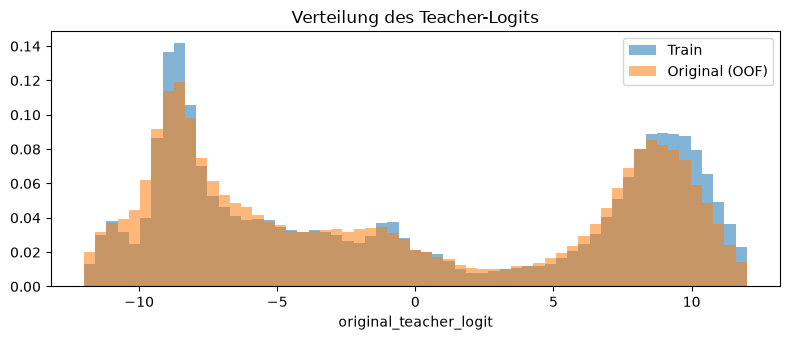

In [4]:
d0 = get_data("base")
auc_tr = roc_auc_score(d0.y, d0.X["original_teacher_logit"])
auc_or = roc_auc_score(d0.y_orig, d0.X_orig["original_teacher_logit"])
print(f"Teacher-AUC auf Original (OOF): {auc_or:.4f}")
print(f"Teacher-AUC auf Train          : {auc_tr:.4f}")
print(f"-> Differenz: {auc_or - auc_tr:+.4f}  (gross = Signal auf Original deutlich schaerfer)")

fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.linspace(-12, 12, 60)
ax.hist(d0.X["original_teacher_logit"], bins=bins, alpha=0.55, density=True, label="Train")
ax.hist(d0.X_orig["original_teacher_logit"], bins=bins, alpha=0.55, density=True, label="Original (OOF)")
ax.set_xlabel("original_teacher_logit"); ax.set_title("Verteilung des Teacher-Logits"); ax.legend()
plt.tight_layout(); plt.show()

## CV-Schleife (Erweiterung der Runde-1-Version)
Neu gegenüber Runde 1: Gewicht für Original-Zeilen, wählbarer Teacher-Modus, Zusatz-Features (`extra`) und zusätzliche In-Fold-Target-Encodings (`te_extra`). Alles andere ist identisch (gleiche Folds, nur AUC als Metrik).

In [5]:
def te_map(k_train, y_train, k_valid, smooth=20.0):
    prior = y_train.mean()
    stats = pd.DataFrame({"k": k_train, "y": y_train}).groupby("k")["y"].agg(["sum", "count"])
    mapping = (stats["sum"] + prior * smooth) / (stats["count"] + smooth)
    return pd.Series(k_valid).map(mapping).fillna(prior).values.astype(np.float32)

DEFAULTS = dict(data_key="base", teacher="keep", drop=[], use_orig_rows=False, orig_weight=1.0,
                use_te=True, extra=[], te_extra=[], parent="r0_ref", desc="")

def run_cv_lgbm(spec, seed=ABL_SEED, n_splits=ABL_SPLITS):
    d = get_data_teacher(spec["data_key"], spec["teacher"])
    drop = sorted({c for g in spec["drop"] for c in cols_of(d.X.columns, g)})
    X, y = d.X.drop(columns=drop), d.y
    Xo = yo = None
    if d.X_orig is not None and spec["use_orig_rows"]:
        Xo, yo = d.X_orig.drop(columns=drop), d.y_orig
    ex = get_extra(spec["data_key"]) if (spec["extra"] or spec["te_extra"]) else None

    for g in spec["extra"]:                      # Zusatz-Features anhaengen
        X = pd.concat([X, ex[g][0]], axis=1)
        if Xo is not None: Xo = pd.concat([Xo, ex[g][2]], axis=1)

    te_specs = []                                # (Spaltenname, Key-Train, Key-Orig)
    if spec["use_te"] and "Route_ID" in X.columns:
        te_specs.append(("Route_Target_Enc", X["Route_ID"], Xo["Route_ID"] if Xo is not None else None))
    for k in spec["te_extra"]:
        te_specs.append((f"TE_{k}", ex["keys"][0][k], ex["keys"][2][k] if Xo is not None else None))

    oof = np.zeros(len(X)); fold_aucs, best_its = [], []
    imp = pd.Series(0.0, index=list(X.columns) + [t[0] for t in te_specs])
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for tr, va in skf.split(X, y):
        X_tr, y_tr = X.iloc[tr].copy(), y.iloc[tr]
        X_va, y_va = X.iloc[va].copy(), y.iloc[va]
        Xo_f = Xo.copy() if Xo is not None else None

        for col, k_all, k_orig in te_specs:
            k_tr = k_all.iloc[tr]
            inner = np.zeros(len(X_tr), dtype=np.float32)
            for a, b in StratifiedKFold(5, shuffle=True, random_state=seed).split(X_tr, y_tr):
                inner[b] = te_map(k_tr.iloc[a], y_tr.iloc[a], k_tr.iloc[b])
            X_tr[col] = inner
            X_va[col] = te_map(k_tr, y_tr, k_all.iloc[va])
            if Xo_f is not None:
                Xo_f[col] = te_map(k_tr, y_tr, k_orig)

        w = np.ones(len(X_tr))
        if Xo_f is not None:
            X_tr = pd.concat([X_tr, Xo_f], ignore_index=True)
            y_tr = pd.concat([y_tr, yo], ignore_index=True)
            w = np.r_[w, np.full(len(Xo_f), spec["orig_weight"])]

        params = {**cfg.PARAMS["lgbm"], **LGBM_OVERRIDE}
        model = lgb.LGBMClassifier(**params, metric="auc", random_state=seed, verbosity=-1, n_jobs=-1)
        model.fit(X_tr, y_tr, sample_weight=w, eval_set=[(X_va, y_va)], eval_metric="auc",
                  callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False)])
        p = model.predict_proba(X_va)[:, 1]
        oof[va] = p
        fold_aucs.append(roc_auc_score(y_va, p)); best_its.append(model.best_iteration_)
        imp = imp.add(pd.Series(model.booster_.feature_importance("gain"), index=model.booster_.feature_name()), fill_value=0.0)

    return dict(auc=roc_auc_score(y, oof), fold_aucs=fold_aucs, n_features=X_tr.shape[1],
                mean_best_iter=float(np.mean(best_its)), importance=imp / imp.sum())

## Ergebnisverwaltung (Resume über CSV)

In [6]:
SPECS = {}      # Name -> Spezifikation (fuer Tabelle, Kombination)
results = {}    # (Name, Seed) -> Ergebnis

def save_results():
    rows = [dict(variant=n, seed=s, auc=r["auc"], fold_aucs=json.dumps(r["fold_aucs"]), n_features=r["n_features"],
                 mean_best_iter=r["mean_best_iter"], time=r.get("time", np.nan), desc=r.get("desc", ""),
                 parent=r.get("parent", "r0_ref")) for (n, s), r in results.items()]
    pd.DataFrame(rows).to_csv(RESULTS_CSV, index=False)

def load_results():
    if RESUME and RESULTS_CSV.exists():
        for _, row in pd.read_csv(RESULTS_CSV).iterrows():
            results[(row["variant"], int(row["seed"]))] = dict(
                auc=row["auc"], fold_aucs=json.loads(row["fold_aucs"]), n_features=int(row["n_features"]),
                mean_best_iter=row["mean_best_iter"], time=row["time"], desc=row["desc"],
                parent=row.get("parent", "r0_ref"), importance=None)
        print(f"{len(results)} Ergebnisse aus {RESULTS_CSV.name} geladen.")

def run_variant(name, spec, seed=ABL_SEED):
    spec = {**DEFAULTS, **spec}
    SPECS[name] = spec
    key = (name, seed)
    if key in results:
        r = results[key]
        print(f"{name:34s} seed={seed:<5d} AUC={r['auc']:.6f}  (aus CSV)")
        return r
    t0 = time.time()
    r = run_cv_lgbm(spec, seed)
    r.update(time=time.time() - t0, desc=spec["desc"], parent=spec["parent"])
    results[key] = r
    save_results()
    print(f"{name:34s} seed={seed:<5d} AUC={r['auc']:.6f}  Features={r['n_features']:3d}  "
          f"best_it~{r['mean_best_iter']:.0f}  {r['time']:.0f}s")
    return r

load_results()

## 1) Referenz und Rauschgrenze
- `v0_baseline`: `fs06` unverändert (Original-Zeilen **an**) – zum Vergleich mit Runde 1.
- `r0_ref`: **neue Referenz** = Runde-1-Gewinner `v3` (Teacher ja, Original-Zeilen aus, Statistiken gemeinsam).

In [7]:
run_variant("v0_baseline", dict(use_orig_rows=True, parent="v0_baseline", desc="fs06 unveraendert (Runde 1)"))

for s in NOISE_SEEDS:
    run_variant("r0_ref", dict(parent="r0_ref", desc="Referenz = v3: Teacher ja, Original-Zeilen aus"), seed=s)

noise_aucs = [results[("r0_ref", s)]["auc"] for s in NOISE_SEEDS]
NOISE = float(np.std(noise_aucs, ddof=1)) if len(noise_aucs) > 1 else 0.0
THR = max(2 * NOISE, MIN_EFFECT)
print(f"\nReferenz-AUCs: {[round(a, 6) for a in noise_aucs]} | Rauschen: {NOISE:.6f} | Schwelle: {THR:.6f}")
print(f"Referenz gegenueber v0_baseline: {results[('r0_ref', ABL_SEED)]['auc'] - results[('v0_baseline', ABL_SEED)]['auc']:+.6f}")

v0_baseline                        seed=42    AUC=0.960257  Features= 92  best_it~259  68s
r0_ref                             seed=42    AUC=0.960811  Features= 92  best_it~207  57s
r0_ref                             seed=2026  AUC=0.960783  Features= 92  best_it~225  54s
r0_ref                             seed=10    AUC=0.960774  Features= 92  best_it~229  53s

Referenz-AUCs: [0.960811, 0.960783, 0.960774] | Rauschen: 0.000019 | Schwelle: 0.000039
Referenz gegenueber v0_baseline: +0.000554


## 2) Block A & B: `v3` + `v8` kombinieren, dann schlanker machen

In [8]:
run_variant("rA_v3_plus_v8",
            dict(data_key="orig_sep", parent="r0_ref", desc="A: Teacher, keine Orig-Zeilen, Orig mit eigenen Statistiken"))
run_variant("rB_A_slim",
            dict(data_key="orig_sep", drop=["interact_group", "combos"], parent="rA_v3_plus_v8",
                 desc="B: A ohne interact_group + combos"))

r0, rA, rB = (results[(n, ABL_SEED)]["auc"] for n in ["r0_ref", "rA_v3_plus_v8", "rB_A_slim"])
BASE_KEY = "orig_sep" if rA - r0 > -THR else "base"
PRUNE = ["interact_group", "combos"] if (BASE_KEY == "orig_sep" and rB - rA >= -THR) else []
PARENT = ("rB_A_slim" if PRUNE else "rA_v3_plus_v8") if BASE_KEY == "orig_sep" else "r0_ref"
print(f"\nA vs Referenz: {rA - r0:+.6f}  -> BASE_KEY = '{BASE_KEY}'")
print(f"B vs A       : {rB - rA:+.6f}  -> Schlank-machen {'uebernommen' if PRUNE else 'nicht uebernommen'}: {PRUNE}")
print(f"Eltern-Variante fuer Block C-E: '{PARENT}'")

[Daten] lade 'orig_sep' ...
Originaldatensatz geladen: (129880, 22)
train (699635, 23) | test (299844, 22) | sample_submission (299844, 2)
Trainiere Original-Data Teacher Modell...
Teacher OOF-AUC auf Original: 0.994932
Original-Data Teacher Feature erfolgreich generiert!
Hinweis: Test hat keine fehlenden Arrival-Delay-Werte -> 'Arrival_Delay_Missing' entfernt
Feature-Set fs06: 91 Features (kategorisch: 9)
rA_v3_plus_v8                      seed=42    AUC=0.960692  Features= 92  best_it~246  75s
rB_A_slim                          seed=42    AUC=0.960675  Features= 81  best_it~198  47s

A vs Referenz: -0.000119  -> BASE_KEY = 'base'
B vs A       : -0.000018  -> Schlank-machen nicht uebernommen: []
Eltern-Variante fuer Block C-E: 'r0_ref'


## 3) Block C & D: Teacher nur auf Rohspalten, Original-Zeilen mit Gewicht

In [9]:
P = dict(data_key=BASE_KEY, drop=list(PRUNE), parent=PARENT)

run_variant("rC_teacher_raw", {**P, "teacher": "raw", "desc": "C: Teacher nur auf Rohspalten"})
run_variant("rD1_orig_rows_w0.2", {**P, "use_orig_rows": True, "orig_weight": 0.2, "desc": "D1: Original-Zeilen Gewicht 0.2 + Teacher"})
run_variant("rD2_orig_rows_w0.5", {**P, "use_orig_rows": True, "orig_weight": 0.5, "desc": "D2: Original-Zeilen Gewicht 0.5 + Teacher"})

[Teacher 'raw'] 40 Features (ohne 51 gruppenbasierte) ...
[Teacher 'raw'] OOF-AUC Original: 0.994881 | AUC auf Train: 0.954708
rC_teacher_raw                     seed=42    AUC=0.960743  Features= 92  best_it~230  64s
rD1_orig_rows_w0.2                 seed=42    AUC=0.960653  Features= 92  best_it~210  53s
rD2_orig_rows_w0.5                 seed=42    AUC=0.960576  Features= 92  best_it~216  55s


{'auc': 0.960575642966957,
 'fold_aucs': [0.9610388648229218,
  0.9594995082693786,
  0.9612379134192409,
  0.9604956343513321,
  0.9606853246892421],
 'n_features': 92,
 'mean_best_iter': 216.0,
 'importance': Age                                  0.002218
 Flight_Distance                      0.000457
 Inflight_wifi_service                0.001438
 Departure/Arrival_time_convenient    0.000262
 Ease_of_Online_booking               0.000927
                                        ...   
 Group_Dist_Std                       0.000044
 Diff_From_Group_Dist_Mean            0.001296
 Class_DepDelay_Mean                  0.000028
 original_teacher_logit               0.853666
 Route_Target_Enc                     0.003693
 Length: 92, dtype: float64,
 'time': 55.252018213272095,
 'desc': 'D2: Original-Zeilen Gewicht 0.5 + Teacher',
 'parent': 'r0_ref'}

## 4) Block E: Route-Signal vertiefen
- `rE1`/`rE2`: Trägt `Route_Mean_*` oder `Route_Freq*` das Signal? (Ausbau-Test)
- `rE3`: zusätzliche Aggregate je Route (Std, Anteile Business/Loyal/Personal, Mittel von `Rating_Mean`)
- `rE4`: Abweichung jedes Ratings vom Routen-Mittel (`RDiff_*`, 13 Features)
- `rE5`/`rE6`: In-Fold-Target-Encoding für Route×Class bzw. Route×Reise-Typ

In [10]:
run_variant("rE1_no_route_mean", {**P, "drop": P["drop"] + ["route_mean"], "desc": "E1: Route_Mean_* raus"})
run_variant("rE2_no_route_freq", {**P, "drop": P["drop"] + ["route_freq"], "desc": "E2: Route_Freq* raus"})
run_variant("rE3_route_extra",   {**P, "extra": ["route_extra"], "desc": "E3: + Route-Zusatzaggregate"})
run_variant("rE4_route_diff",    {**P, "extra": ["route_diff"], "desc": "E4: + Abweichung vom Route-Mittel"})
run_variant("rE5_te_route_class",  {**P, "te_extra": ["route_class"], "desc": "E5: + TE Route x Class"})
run_variant("rE6_te_route_travel", {**P, "te_extra": ["route_travel"], "desc": "E6: + TE Route x Reise-Typ"})

rE1_no_route_mean                  seed=42    AUC=0.960486  Features= 76  best_it~196  43s
rE2_no_route_freq                  seed=42    AUC=0.960707  Features= 89  best_it~214  50s
rE3_route_extra                    seed=42    AUC=0.960761  Features= 99  best_it~237  57s
rE4_route_diff                     seed=42    AUC=0.960741  Features=105  best_it~204  53s
rE5_te_route_class                 seed=42    AUC=0.960708  Features= 93  best_it~183  46s
rE6_te_route_travel                seed=42    AUC=0.960728  Features= 93  best_it~212  50s


{'auc': 0.9607276668867191,
 'fold_aucs': [0.9610303134133311,
  0.9597181457325497,
  0.9613867251523976,
  0.9607515061752837,
  0.9608218067061494],
 'n_features': 93,
 'mean_best_iter': 212.2,
 'importance': Age                                  0.002608
 Flight_Distance                      0.000810
 Inflight_wifi_service                0.008216
 Departure/Arrival_time_convenient    0.000166
 Ease_of_Online_booking               0.000636
                                        ...   
 Diff_From_Group_Dist_Mean            0.001329
 Class_DepDelay_Mean                  0.000009
 original_teacher_logit               0.807171
 Route_Target_Enc                     0.003190
 TE_route_travel                      0.003319
 Length: 93, dtype: float64,
 'time': 49.96488976478577,
 'desc': 'E6: + TE Route x Reise-Typ',
 'parent': 'r0_ref'}

## 5) Ergebnistabelle (Δ je Variante gegenüber ihrer Eltern-Variante)

In [11]:
def build_table():
    rows = []
    ref0 = results[("v0_baseline", ABL_SEED)]
    for (name, seed), r in results.items():
        if seed != ABL_SEED:
            continue
        par = results.get((r.get("parent", "r0_ref"), ABL_SEED))
        if par is None or name == r.get("parent"):
            delta, better, code_ = np.nan, np.nan, "referenz"
        else:
            delta = r["auc"] - par["auc"]
            better = int((np.array(r["fold_aucs"]) > np.array(par["fold_aucs"])).sum())
            code_ = "besser" if delta > THR else ("schlechter" if delta < -THR else "neutral")
        rows.append(dict(variant=name, parent=r.get("parent", ""), auc=r["auc"], delta_vs_parent=delta,
                         better_folds=better, delta_vs_v0=r["auc"] - ref0["auc"], n_features=r["n_features"],
                         urteil=code_, desc=r.get("desc", "")))
    return pd.DataFrame(rows).set_index("variant")

table = build_table()
try:
    display(table.style.format({"auc": "{:.6f}", "delta_vs_parent": "{:+.6f}", "delta_vs_v0": "{:+.6f}"})
            .background_gradient(subset=["delta_vs_v0"], cmap="RdYlGn"))
except Exception:
    display(table.round(6))
print(f"Schwelle fuer echten Effekt: +/- {THR:.6f} | Gewinner: besser UND in >= {WIN_MIN_FOLDS}/{ABL_SPLITS} Folds besser")

,parent,auc,delta_vs_parent,better_folds,delta_vs_v0,n_features,urteil,desc
variant,,,,,,,,
v0_baseline,v0_baseline,0.960257,NaN,NaN,0.000000,92,referenz,fs06 unveraendert (Runde 1)
r0_ref,r0_ref,0.960811,NaN,NaN,0.000554,92,referenz,"Referenz = v3: Teacher ja, Original-Zeilen aus"
rA_v3_plus_v8,r0_ref,0.960692,-0.000119,1.0,0.000435,92,schlechter,"A: Teacher, keine Orig-Zeilen, Orig mit eigene..."
rB_A_slim,rA_v3_plus_v8,0.960675,-0.000018,2.0,0.000417,81,neutral,B: A ohne interact_group + combos
rC_teacher_raw,r0_ref,0.960743,-0.000068,3.0,0.000486,92,schlechter,C: Teacher nur auf Rohspalten
rD1_orig_rows_w0.2,r0_ref,0.960653,-0.000158,0.0,0.000396,92,schlechter,D1: Original-Zeilen Gewicht 0.2 + Teacher
rD2_orig_rows_w0.5,r0_ref,0.960576,-0.000236,0.0,0.000318,92,schlechter,D2: Original-Zeilen Gewicht 0.5 + Teacher
rE1_no_route_mean,r0_ref,0.960486,-0.000325,0.0,0.000229,76,schlechter,E1: Route_Mean_* raus
rE2_no_route_freq,r0_ref,0.960707,-0.000104,0.0,0.000450,89,schlechter,E2: Route_Freq* raus


Schwelle fuer echten Effekt: +/- 0.000039 | Gewinner: besser UND in >= 4/5 Folds besser


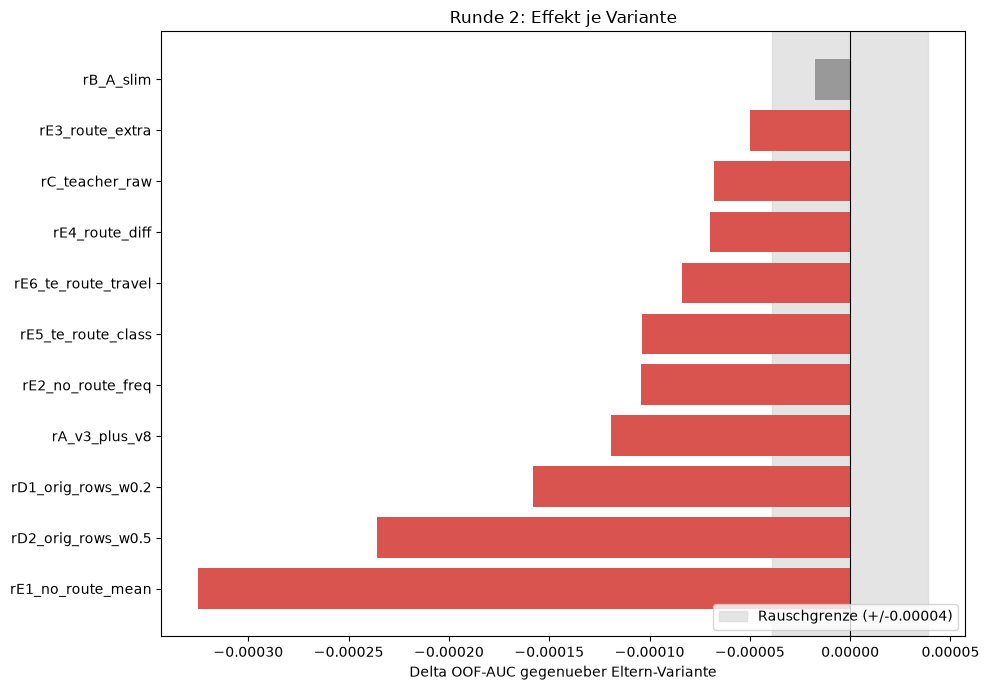

In [12]:
t = table[table["urteil"].isin(["besser", "schlechter", "neutral"])].sort_values("delta_vs_parent")
col = t["urteil"].map({"besser": "#5cb85c", "neutral": "#999999", "schlechter": "#d9534f"})
fig, ax = plt.subplots(figsize=(10, 0.5 * len(t) + 1.5))
ax.axvspan(-THR, THR, color="lightgray", alpha=0.6, label=f"Rauschgrenze (+/-{THR:.5f})")
ax.barh(t.index, t["delta_vs_parent"], color=col)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Delta OOF-AUC gegenueber Eltern-Variante")
ax.set_title("Runde 2: Effekt je Variante")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

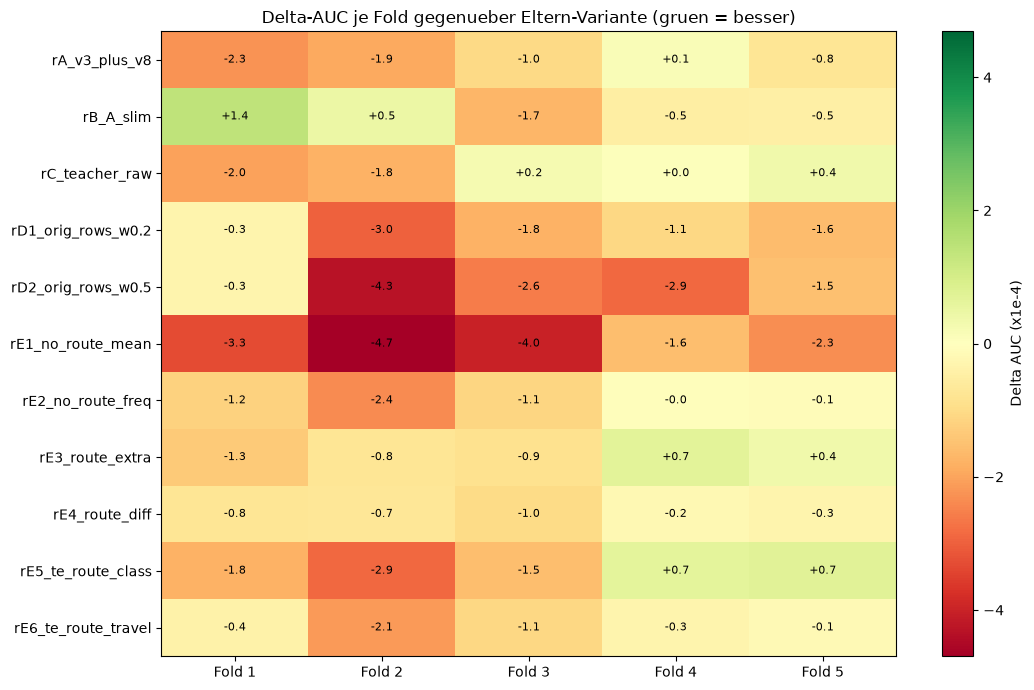

In [13]:
names = [n for n in table.index if table.loc[n, "urteil"] in ("besser", "schlechter", "neutral")]
M = np.array([(np.array(results[(n, ABL_SEED)]["fold_aucs"]) -
               np.array(results[(table.loc[n, "parent"], ABL_SEED)]["fold_aucs"])) * 1e4 for n in names])
v = max(abs(M).max(), 0.5)
fig, ax = plt.subplots(figsize=(1.2 * M.shape[1] + 5, 0.5 * len(names) + 1.5))
im = ax.imshow(M, cmap="RdYlGn", vmin=-v, vmax=v, aspect="auto")
ax.set_xticks(range(M.shape[1])); ax.set_xticklabels([f"Fold {i+1}" for i in range(M.shape[1])])
ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, i, f"{M[i, j]:+.1f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="Delta AUC (x1e-4)")
ax.set_title("Delta-AUC je Fold gegenueber Eltern-Variante (gruen = besser)")
plt.tight_layout(); plt.show()

## 6) Finale Kombination aller Gewinner
Gewinner = Variante ist über der Rauschgrenze **und** in mindestens `WIN_MIN_FOLDS` Folds besser als ihre Eltern-Variante. Ihre Einstellungen werden zusammengeführt (Zusatz-Features und Target-Encodings addieren sich, Teacher-Modus/Gewicht werden übernommen, Ausbau-Gruppen entfallen).
Mit `WINNERS = [...]` kannst du die Auswahl auch von Hand überschreiben.

In [14]:
WINNERS = None   # z. B. ["rC_teacher_raw", "rE3_route_extra"]; None = automatisch

def merge_specs(names):
    spec = {**DEFAULTS, **SPECS[PARENT], "parent": PARENT}
    for n in names:
        s = {**DEFAULTS, **SPECS[n]}
        spec["extra"] = sorted(set(spec["extra"]) | set(s["extra"]))
        spec["te_extra"] = sorted(set(spec["te_extra"]) | set(s["te_extra"]))
        spec["drop"] = sorted(set(spec["drop"]) | set(s["drop"]))
        if s["teacher"] != "keep": spec["teacher"] = s["teacher"]
        if s["use_orig_rows"]:
            spec["use_orig_rows"], spec["orig_weight"] = True, s["orig_weight"]
    return spec

tab = build_table()
if WINNERS is None:
    WINNERS = [n for n in tab.index
               if tab.loc[n, "urteil"] == "besser" and tab.loc[n, "better_folds"] >= WIN_MIN_FOLDS
               and n.startswith(("rC", "rD", "rE")) and tab.loc[n, "parent"] == PARENT]
print("Gewinner:", WINNERS)

if WINNERS:
    spec = merge_specs(WINNERS)
    spec["desc"] = "Final: " + ", ".join(WINNERS)
    spec["parent"] = PARENT
    fin = run_variant("r_final", spec)
    par = results[(PARENT, ABL_SEED)]; v0 = results[("v0_baseline", ABL_SEED)]
    print(f"\nEltern ({PARENT}): {par['auc']:.6f}")
    print(f"Final            : {fin['auc']:.6f}  ({fin['n_features']} Features)")
    print(f"Delta Eltern     : {fin['auc'] - par['auc']:+.6f} | bessere Folds: "
          f"{int((np.array(fin['fold_aucs']) > np.array(par['fold_aucs'])).sum())}/{ABL_SPLITS}")
    print(f"Delta v0 (fs06)  : {fin['auc'] - v0['auc']:+.6f}")
else:
    print("Kein Gewinner ueber der Rauschgrenze - Eltern-Variante bleibt die beste Konfiguration.")

Gewinner: []
Kein Gewinner ueber der Rauschgrenze - Eltern-Variante bleibt die beste Konfiguration.


## 7) Empfehlung für die Pipeline

In [15]:
best = max([k for k in results if k[1] == ABL_SEED], key=lambda k: results[k]["auc"])
print(f"Beste Variante in dieser Runde: {best[0]}  (AUC {results[best]['auc']:.6f})\n")
sp = {**DEFAULTS, **SPECS.get(best[0], {})}
print("Config-Schalter (src/config.py, siehe src_v2/):")
print(f"  USE_ORIG_ROWS = {sp['use_orig_rows']}")
print(f"  ORIG_IN_STATS = {sp['data_key'] == 'base'}")
todo = []
if sp["teacher"] != "keep": todo.append("Teacher nur auf Rohspalten trainieren (data.py anpassen)")
if sp["use_orig_rows"] and sp["orig_weight"] != 1.0: todo.append(f"Gewicht {sp['orig_weight']} fuer Original-Zeilen (cv.py/models.py: sample_weight)")
if sp["extra"]: todo.append(f"Zusatz-Features einbauen: {sp['extra']} (features.py)")
if sp["te_extra"]: todo.append(f"In-Fold-Target-Encodings einbauen: {sp['te_extra']} (cv.py)")
if sp["drop"]: todo.append(f"Gruppen entfernen: {sp['drop']} (neues Feature-Set, z. B. fs07)")
print("Noch umzusetzen (sag Bescheid, dann baue ich es in die Pipeline):")
for t_ in todo or ["nichts, die Config-Schalter reichen"]:
    print("  -", t_)

Beste Variante in dieser Runde: r0_ref  (AUC 0.960811)

Config-Schalter (src/config.py, siehe src_v2/):
  USE_ORIG_ROWS = False
  ORIG_IN_STATS = True
Noch umzusetzen (sag Bescheid, dann baue ich es in die Pipeline):
  - nichts, die Config-Schalter reichen


## Lesehilfe
- **Teacher-AUC auf Train deutlich < 0.995:** bestätigt, dass Original-Zeilen im Training ein zu scharfes Teacher-Signal liefern → Original-Zeilen weglassen oder nur klein gewichten (D).
- **A > Referenz:** eigene Statistiken fürs Original lohnen sich auch zusammen mit `v3`.
- **C besser:** Der Teacher litt unter Skalenunterschieden der Gruppenstatistiken.
- **E1/E2 stark schlechter:** der jeweilige Route-Teil trägt das Signal → dort weitersuchen. **E3–E6 besser:** neue Information gefunden, ausbauen.
- Effekte addieren sich nicht zwingend – deshalb der Kombinationslauf am Ende. Entscheidend ist `delta_vs_v0` der finalen Variante.
- Gilt für LGBM mit 1 Seed; für XGB/CatBoost sind es Hinweise, keine Beweise.